# ML Lab 3
## Name: Saptanshu Wanjari
### Class: A A2
### Roll No: 18

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
data = pd.read_csv("enjoy.csv")
print("Shape:", data.shape)
data.head()

Shape: (10, 7)


,Sky,AirTemp,Humidity,Wind,Water,Forecast,EnjoySport
0,Sunny,Warm,Normal,Strong,Warm,Same,Yes
1,Sunny,Warm,High,Strong,Warm,Same,Yes
2,Rainy,Cold,High,Strong,Warm,Change,No
3,Sunny,Warm,High,Strong,Cool,Change,Yes
4,Sunny,Cold,Normal,Weak,Warm,Same,No


In [3]:
data.info()
print()
data.describe()

<class 'pandas.DataFrame'>
RangeIndex: 10 entries, 0 to 9
Data columns (total 7 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   Sky         10 non-null     str  
 1   AirTemp     10 non-null     str  
 2   Humidity    10 non-null     str  
 3   Wind        10 non-null     str  
 4   Water       10 non-null     str  
 5   Forecast    10 non-null     str  
 6   EnjoySport  10 non-null     str  
dtypes: str(7)
memory usage: 692.0 bytes



,Sky,AirTemp,Humidity,Wind,Water,Forecast,EnjoySport
count,10,10,10,10,10,10,10
unique,3,2,2,2,2,2,2
top,Sunny,Warm,Normal,Strong,Warm,Same,Yes
freq,7,8,5,5,6,7,6


In [4]:
print("Missing values per column:")
print(data.isnull().sum())
print("\nTotal missing:", data.isnull().sum().sum())

Missing values per column:
Sky           0
AirTemp       0
Humidity      0
Wind          0
Water         0
Forecast      0
EnjoySport    0
dtype: int64

Total missing: 0


In [5]:
dup = data.duplicated().sum()
print("Duplicate rows:", dup)
print("Total rows:", len(data))
print("Unique rows:", len(data) - dup)

Duplicate rows: 0
Total rows: 10
Unique rows: 10


In [6]:
data_encoded = data.copy()
for col in data_encoded.columns:
    data_encoded[col] = data_encoded[col].astype('category').cat.codes
print("Encoded (0/1/2/... per category):")
data_encoded.head()

Encoded (0/1/2/... per category):


,Sky,AirTemp,Humidity,Wind,Water,Forecast,EnjoySport
0,2,1,1,0,1,1,1
1,2,1,0,0,1,1,1
2,1,0,0,0,1,0,0
3,2,1,0,0,0,0,1
4,2,0,1,1,1,1,0


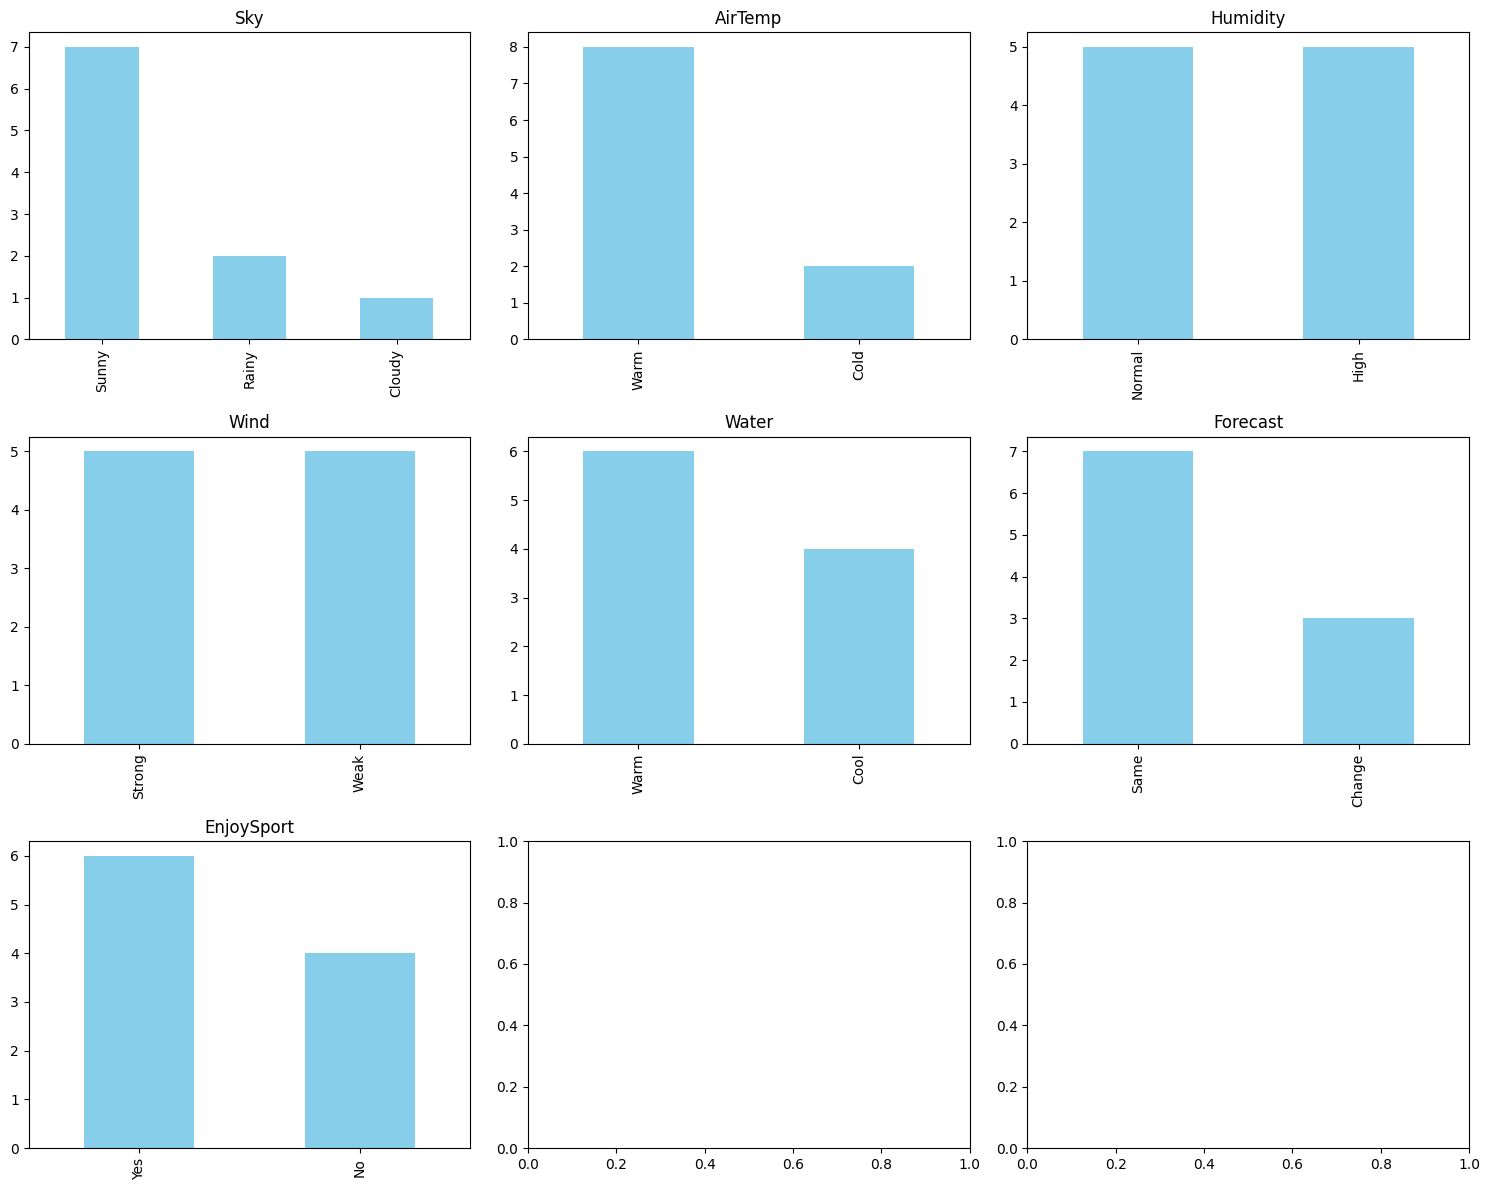

In [7]:
fig, axes = plt.subplots(3, 3, figsize=(15, 12))
axes = axes.flatten()
for i, col in enumerate(data.columns):
    data[col].value_counts().plot(kind='bar', ax=axes[i], color='skyblue')
    axes[i].set_title(col)
    axes[i].set_xlabel('')
plt.tight_layout()
plt.show()

/tmp/ipykernel_16952/3173743255.py:1: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='EnjoySport', data=data, palette='Set2')


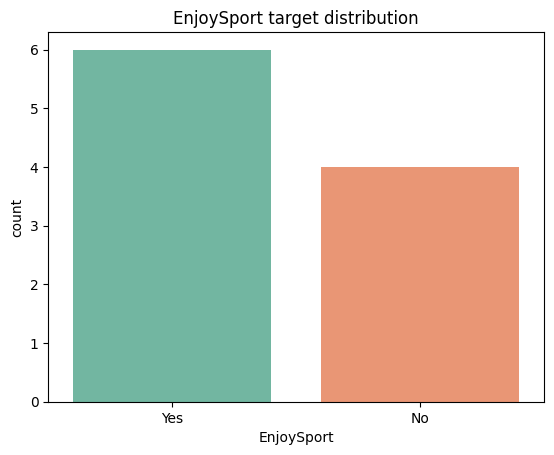

EnjoySport
Yes    6
No     4
Name: count, dtype: int64


In [8]:
sns.countplot(x='EnjoySport', data=data, palette='Set2')
plt.title('EnjoySport target distribution')
plt.show()
print(data['EnjoySport'].value_counts())

In [9]:
X = data.iloc[:, :-1].values
y = data.iloc[:, -1].values
print("X (features):\n", X)
print("\ny (target):\n", y)
print("\nX shape:", X.shape, "| y shape:", y.shape)

X (features):
 [['Sunny' 'Warm' 'Normal' 'Strong' 'Warm' 'Same']
 ['Sunny' 'Warm' 'High' 'Strong' 'Warm' 'Same']
 ['Rainy' 'Cold' 'High' 'Strong' 'Warm' 'Change']
 ['Sunny' 'Warm' 'High' 'Strong' 'Cool' 'Change']
 ['Sunny' 'Cold' 'Normal' 'Weak' 'Warm' 'Same']
 ['Cloudy' 'Warm' 'Normal' 'Weak' 'Warm' 'Same']
 ['Sunny' 'Warm' 'Normal' 'Weak' 'Cool' 'Same']
 ['Rainy' 'Warm' 'High' 'Weak' 'Cool' 'Change']
 ['Sunny' 'Warm' 'Normal' 'Strong' 'Cool' 'Same']
 ['Sunny' 'Warm' 'High' 'Weak' 'Warm' 'Same']]

y (target):
 <StringArray>
['Yes', 'Yes', 'No', 'Yes', 'No', 'No', 'Yes', 'No', 'Yes', 'Yes']
Length: 10, dtype: str

X shape: (10, 6) | y shape: (10,)


In [10]:
def find_s(X, y):
    hypothesis = None
    print("Initial hypothesis:", hypothesis)
    for i in range(len(X)):
        if y[i] == "Yes":
            if hypothesis is None:
                hypothesis = X[i].copy()
            else:
                for j in range(len(hypothesis)):
                    if hypothesis[j] != X[i][j]:
                        hypothesis[j] = '?'
        print("\nAfter training example", i + 1, ":", hypothesis)
    return hypothesis

final_hypothesis = find_s(X, y)
print("\nFinal hypothesis:", final_hypothesis)

Initial hypothesis: None

After training example 1 : ['Sunny' 'Warm' 'Normal' 'Strong' 'Warm' 'Same']

After training example 2 : ['Sunny' 'Warm' '?' 'Strong' 'Warm' 'Same']

After training example 3 : ['Sunny' 'Warm' '?' 'Strong' 'Warm' 'Same']

After training example 4 : ['Sunny' 'Warm' '?' 'Strong' '?' '?']

After training example 5 : ['Sunny' 'Warm' '?' 'Strong' '?' '?']

After training example 6 : ['Sunny' 'Warm' '?' 'Strong' '?' '?']

After training example 7 : ['Sunny' 'Warm' '?' '?' '?' '?']

After training example 8 : ['Sunny' 'Warm' '?' '?' '?' '?']

After training example 9 : ['Sunny' 'Warm' '?' '?' '?' '?']

After training example 10 : ['Sunny' 'Warm' '?' '?' '?' '?']

Final hypothesis: ['Sunny' 'Warm' '?' '?' '?' '?']


In [11]:
def covers(g, h):
    return all(g[j] == "?" or g[j] == h[j] for j in range(len(g)))

def candidate_elimination(concepts, target):
    S = concepts[0].copy()
    G = [["?" for _ in range(len(S))]]
    print("Initial S:", S)
    print("Initial G:", G)
    for i, (h, t) in enumerate(zip(concepts, target)):
        if t == "Yes":
            for j in range(len(S)):
                if S[j] != h[j]:
                    S[j] = "?"
            G = [g for g in G if covers(g, h)]
        else:
            keep, spec = [], []
            for g in G:
                if covers(g, h):
                    for j in range(len(g)):
                        if g[j] == "?" and S[j] != "?":
                            s2 = list(g)
                            s2[j] = S[j]
                            if not covers(s2, h) and s2 not in spec:
                                spec.append(s2)
                else:
                    keep.append(g)
            G = keep + spec
            dedup, seen = [], set()
            for g in G:
                k = tuple(g)
                if k not in seen:
                    seen.add(k)
                    dedup.append(g)
            G = [g for g in dedup if not any(
                g != g2 and all(g2[j] == "?" or g2[j] == g[j] for j in range(len(g)))
                for g2 in dedup)]
        print("\nAfter example", i + 1, "(" + t + "):")
        print("S:", S)
        print("G:", G)
    return S, G

S, G = candidate_elimination(X, y)
print("\nFinal S:", S)
print("Final G:", G)

Initial S: ['Sunny' 'Warm' 'Normal' 'Strong' 'Warm' 'Same']
Initial G: [['?', '?', '?', '?', '?', '?']]

After example 1 (Yes):
S: ['Sunny' 'Warm' 'Normal' 'Strong' 'Warm' 'Same']
G: [['?', '?', '?', '?', '?', '?']]

After example 2 (Yes):
S: ['Sunny' 'Warm' '?' 'Strong' 'Warm' 'Same']
G: [['?', '?', '?', '?', '?', '?']]

After example 3 (No):
S: ['Sunny' 'Warm' '?' 'Strong' 'Warm' 'Same']
G: [['Sunny', '?', '?', '?', '?', '?'], ['?', 'Warm', '?', '?', '?', '?'], ['?', '?', '?', '?', '?', 'Same']]

After example 4 (Yes):
S: ['Sunny' 'Warm' '?' 'Strong' '?' '?']
G: [['Sunny', '?', '?', '?', '?', '?'], ['?', 'Warm', '?', '?', '?', '?']]

After example 5 (No):
S: ['Sunny' 'Warm' '?' 'Strong' '?' '?']
G: [['?', 'Warm', '?', '?', '?', '?'], ['Sunny', '?', '?', 'Strong', '?', '?']]

After example 6 (No):
S: ['Sunny' 'Warm' '?' 'Strong' '?' '?']
G: [['Sunny', '?', '?', 'Strong', '?', '?'], ['Sunny', 'Warm', '?', '?', '?', '?'], ['?', 'Warm', '?', 'Strong', '?', '?']]

After example 7 (Yes):
S

## Result

The Find-S algorithm gives a final hypothesis of `['Sunny', 'Warm', '?', '?', '?', '?']`, and Candidate Elimination converges S and G to the same single hypothesis, which means the version space holds exactly one consistent concept.